# 02 — Optimización: QAOA frente a métodos clásicos en la asignación de agentes a focos (Bogotá, SKG)

**TFM — Ventaja cuántica en ciencia de datos** · Juan David Prada Malagón · UNIR

## Qué hace y qué no hace este cuaderno

Reproduce, con los datos de SKG disponibles en `Datos/`, el problema operativo de asignar agentes de campo a focos de incidentes:

1. **Focos:** incidentes de tipo `Choque` de los miércoles a las 8 h (`incidents_movility.csv`), agrupados con DBSCAN (métrica haversine, 500 m).
2. **Bases de agentes:** posición mediana de los registros GPS de cada localidad (`agents.csv`).
3. **Problema completo:** localización-asignación exacta con PuLP/CBC (todos los focos y agentes). Es la referencia de negocio; **no** se compara con QAOA, porque exigiría una variable binaria (un qubit) por pareja foco-agente, con 19 agentes y más de 150 variables en total, fuera del alcance de un simulador de vector de estados.
4. **Subproblema comparable:** los 10 focos más críticos (con los datos disponibles son todos los focos) y un único agente base, con la restricción de cubrir al menos 5 focos al menor coste. Aquí **los tres métodos resuelven exactamente el mismo problema** y con la misma restricción: fuerza bruta (óptimo), Greedy y QAOA con $p=1$ y $p=2$.

La versión anterior de este cuaderno comparaba QAOA (5 focos cubiertos) con Greedy (10 focos cubiertos) y presentaba una reducción de coste del 70.5 %. Esa comparación no era válida: eran problemas distintos. Aquí se descarta.

## Datos

Los datos de SKG son los entregados para el TFM (carpeta `Datos/`). Los 235 280 incidentes y el *shapefile* de localidades que usaba la versión anterior no están disponibles, por lo que **las cifras de este cuaderno no son comparables con las de aquella versión**.

In [1]:
import time
import warnings
import unicodedata
from math import radians, sin, cos, sqrt, atan2
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

OUT_METRICS = Path("../data/output/metrics")
OUT_FIGURES = Path("../data/output/figures")
DATOS = Path("../../Datos")
OUT_METRICS.mkdir(parents=True, exist_ok=True)
OUT_FIGURES.mkdir(parents=True, exist_ok=True)

N_SUBPROBLEMA = 10      # focos del subproblema (límite del simulador de vector de estados)
CAPACIDAD     = 3       # focos por agente en el problema completo
RANDOM_STATE  = 42
SEMILLAS_QAOA = [42, 43, 44, 45, 46]
print("Entorno configurado")

Entorno configurado


## 1. Incidentes (focos candidatos)

In [2]:
incidentes = pd.read_csv(DATOS / "incidents_movility.csv", parse_dates=["incident_time"], low_memory=False)
print(f"Registros: {len(incidentes):,} | rango: {incidentes['incident_time'].min()} -> {incidentes['incident_time'].max()}")
print(incidentes["category_name"].value_counts().head(5).to_dict())

INCIDENTE, DIA, HORA = "Choque", 2, 8   # miércoles, 8 h
incidentes["dia"] = incidentes["incident_time"].dt.dayofweek
incidentes["hora"] = incidentes["incident_time"].dt.hour
incidents_df = (
    incidentes[(incidentes["category_name"] == INCIDENTE) & (incidentes["dia"] == DIA) & (incidentes["hora"] == HORA)]
    .dropna(subset=["latitude", "longitude"])
    .reset_index(drop=True)
)
print(f"\nFiltro: {INCIDENTE}, día={DIA} (miércoles), hora={HORA} h -> {len(incidents_df)} incidentes")

Registros: 32,991 | rango: 2023-09-01 00:27:00 -> 2023-12-01 00:12:00
{'Choque': 23891, 'Autolesiones': 2590, 'Mantenimiento correctivo': 1536, 'Mantenimiento preventivo': 1076, 'Choque contra objeto fijo': 865}

Filtro: Choque, día=2 (miércoles), hora=8 h -> 238 incidentes


## 2. Bases de agentes por localidad

`agents.csv` contiene registros de telemetría (un registro por lectura GPS). Como base operativa de cada localidad se toma la **mediana** de latitud y longitud de sus lecturas (robusta a lecturas fuera de la ciudad). Los nombres de localidad se normalizan (mayúsculas, sin tildes) porque aparecen en varias grafías.

In [3]:
agentes_raw = pd.read_csv(DATOS / "agents.csv", low_memory=False)

def normalizar(texto):
    sin_tildes = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    return sin_tildes.upper().strip()

agentes_raw["localidad_norm"] = agentes_raw["localidad"].map(normalizar)
agents_df = (
    agentes_raw.groupby("localidad_norm")
    .agg(latitude=("latitude", "median"), longitude=("longitude", "median"), n_lecturas=("id", "count"))
    .reset_index()
    .rename(columns={"localidad_norm": "localidad"})
)
agents_df["agent_id"] = range(len(agents_df))
agents_df["capacity"] = CAPACIDAD
N_AGENTS = len(agents_df)
print(f"Localidades con base: {N_AGENTS}")
print(agents_df[["agent_id", "localidad", "latitude", "longitude", "n_lecturas"]].round(4).to_string(index=False))

Localidades con base: 19
 agent_id          localidad  latitude  longitude  n_lecturas
        0     ANTONIO NARINO    4.5913   -74.1145         575
        1     BARRIOS UNIDOS    4.6664   -74.0731        1257
        2               BOSA    4.6150   -74.1876        3410
        3         CANDELARIA    4.5984   -74.0764         760
        4          CHAPINERO    4.6589   -74.0564        1535
        5     CIUDAD BOLIVAR    4.5841   -74.1562        3103
        6           ENGATIVA    4.7007   -74.1179        5147
        7           FONTIBON    4.6821   -74.1338        4076
        8            KENNEDY    4.6283   -74.1536        5927
        9       LOS MARTIRES    4.6118   -74.0878        2580
       10      PUENTE ARANDA    4.6159   -74.1071       12316
       11 RAFAEL URIBE URIBE    4.5686   -74.1177        2314
       12      SAN CRISTOBAL    4.5683   -74.0914         906
       13           SANTA FE    4.6014   -74.0738        1569
       14               SUBA    4.7375   -74.

## 3. Focos: DBSCAN con métrica haversine (radio 500 m, mínimo 4 incidentes)

In [4]:
from sklearn.cluster import DBSCAN

coords = incidents_df[["latitude", "longitude"]].values
eps_rad = 0.5 / 6371.0088
incidents_df["cluster"] = DBSCAN(eps=eps_rad, min_samples=4, algorithm="ball_tree", metric="haversine").fit_predict(np.radians(coords))

focos_df = (
    incidents_df[incidents_df["cluster"] >= 0]
    .groupby("cluster")
    .agg(lat_centroid=("latitude", "mean"), lon_centroid=("longitude", "mean"),
         n_incidents=("type", "count"), avg_priority=("priority", "mean"))
    .reset_index()
)
focos_df["criticidad"] = focos_df["n_incidents"] * focos_df["avg_priority"]
focos_df["criticidad"] = focos_df["criticidad"] / focos_df["criticidad"].sum()

n_ruido = int((incidents_df["cluster"] == -1).sum())
print(f"Focos: {len(focos_df)} | incidentes en focos: {int((incidents_df['cluster'] >= 0).sum())} | ruido: {n_ruido}")
print(focos_df.sort_values("criticidad", ascending=False).head(5)[["cluster", "n_incidents", "avg_priority", "criticidad"]].round(4).to_string(index=False))

Focos: 10 | incidentes en focos: 48 | ruido: 190
 cluster  n_incidents  avg_priority  criticidad
       5            9       53.1111      0.1866
       4            5       53.6000      0.1046
       3            5       53.4000      0.1042
       0            5       53.0000      0.1034
       8            4       54.0000      0.0843


## 4. Matriz de costes

In [5]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0088
    dlat, dlon = radians(lat2 - lat1), radians(lon2 - lon1)
    a = sin(dlat / 2) ** 2 + cos(radians(lat1)) * cos(radians(lat2)) * sin(dlon / 2) ** 2
    return R * 2 * atan2(sqrt(a), sqrt(1 - a))

n_focos, n_agents = len(focos_df), len(agents_df)
dist = np.array([[haversine(f.lat_centroid, f.lon_centroid, a.latitude, a.longitude)
                  for a in agents_df.itertuples()] for f in focos_df.itertuples()])
criticidad = focos_df["criticidad"].to_numpy()
# coste = distancia / criticidad: los focos más críticos resultan más baratos de atender, es decir, más urgentes
cost = dist / (criticidad[:, None] + 1e-9)

print(f"Focos: {n_focos} | agentes: {n_agents} | variables binarias del problema completo: {n_focos * n_agents}")
print(f"Capacidad total: {n_agents * CAPACIDAD} focos (suficiente: {n_agents * CAPACIDAD >= n_focos})")
print(f"Distancia media {dist.mean():.2f} km | min/max {dist.min():.2f} / {dist.max():.2f} km")

Focos: 10 | agentes: 19 | variables binarias del problema completo: 190
Capacidad total: 57 focos (suficiente: True)
Distancia media 10.17 km | min/max 1.07 / 28.23 km


## 5. Problema completo: localización-asignación exacta (PuLP/CBC)

In [6]:
import pulp

t0 = time.perf_counter()
prob = pulp.LpProblem("AsignacionAgentes", pulp.LpMinimize)
x = {(i, j): pulp.LpVariable(f"x_{i}_{j}", cat="Binary") for i in range(n_focos) for j in range(n_agents)}
prob += pulp.lpSum(cost[i, j] * x[i, j] for i in range(n_focos) for j in range(n_agents))
for i in range(n_focos):
    prob += pulp.lpSum(x[i, j] for j in range(n_agents)) >= 1
for j in range(n_agents):
    prob += pulp.lpSum(x[i, j] for i in range(n_focos)) <= CAPACIDAD
prob.solve(pulp.PULP_CBC_CMD(msg=0))
t_pulp = time.perf_counter() - t0

asignacion_completa = [(i, j) for i in range(n_focos) for j in range(n_agents) if pulp.value(x[i, j]) > 0.5]
coste_completo = pulp.value(prob.objective)
print(f"Estado: {pulp.LpStatus[prob.status]} | coste: {coste_completo:.4f} | focos cubiertos: {len({i for i, _ in asignacion_completa})}/{n_focos} | {t_pulp:.2f} s")

Estado: Optimal | coste: 258.0113 | focos cubiertos: 10/10 | 0.04 s


## 6. Subproblema comparable: mismos datos, misma restricción, mismo objetivo

Se toman los `N_SUBPROBLEMA` focos más críticos y el agente con menor coste total. Se minimiza $\sum_i c_i x_i$ sujeto a $\sum_i x_i \ge k$ con $k=\lfloor N/2\rfloor$. Con 10 variables hay 1 024 asignaciones, así que la fuerza bruta da el óptimo verdadero. Greedy elige los $k$ focos de menor coste (aquí coincide con el óptimo, porque el problema es separable).

In [7]:
top = focos_df.nlargest(N_SUBPROBLEMA, "criticidad").reset_index()
agente = int(cost.sum(axis=0).argmin())
c_sub = cost[top["index"].to_numpy(), agente]
k = max(1, N_SUBPROBLEMA // 2)
print(f"Agente base: {agents_df.loc[agente, 'localidad']} | focos: {N_SUBPROBLEMA} | cobertura mínima k={k}")

def evaluar(bits):
    bits = np.asarray(bits, dtype=int)
    return float(c_sub @ bits), int(bits.sum()) >= k

# Fuerza bruta (óptimo)
t0 = time.perf_counter()
mejor = min((evaluar(b)[0], b) for b in product([0, 1], repeat=N_SUBPROBLEMA) if sum(b) >= k)
t_bruta = time.perf_counter() - t0
coste_opt, bits_opt = mejor

# Greedy: los k focos más baratos
t0 = time.perf_counter()
orden = np.argsort(c_sub)[:k]
bits_greedy = np.zeros(N_SUBPROBLEMA, dtype=int); bits_greedy[orden] = 1
t_greedy = time.perf_counter() - t0
coste_greedy, _ = evaluar(bits_greedy)

print(f"Óptimo (fuerza bruta): coste {coste_opt:.4f}, focos {sum(bits_opt)}  [{t_bruta:.3f} s]")
print(f"Greedy               : coste {coste_greedy:.4f}, focos {int(bits_greedy.sum())}  [{t_greedy * 1000:.3f} ms]")

Agente base: ENGATIVA | focos: 10 | cobertura mínima k=5
Óptimo (fuerza bruta): coste 140.7381, focos 5  [0.001 s]
Greedy               : coste 140.7381, focos 5  [0.073 ms]


### QAOA

El problema se pasa a QUBO con `QuadraticProgramToQubo` (la desigualdad añade variables de holgura, de ahí los 13 qubits) y a Hamiltoniano de Ising. La simulación usa el vector de estados exacto de `qml_v2.mds_qaoa.qaoa_probs`, verificado contra `QAOAAnsatz` de Qiskit (`max_dif_vs_QAOAAnsatz` en `10_mds_qaoa_resumen.json`); aquí se comprueba además que el Hamiltoniano de Ising reproduce el QUBO; el optimizador es COBYLA con 100 evaluaciones como máximo. La solución de cada ejecución es la mejor muestra **factible** de 1 024 disparos con semilla, que es lo que devuelve `MinimumEigenOptimizer`.

In [8]:
import sys
sys.path.insert(0, str(Path("..").resolve()))

from qiskit_algorithms.optimizers import COBYLA
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.converters import QuadraticProgramToQubo
from qml_v2.mds_qaoa import qaoa_probs

qp = QuadraticProgram("subproblema")
for i in range(N_SUBPROBLEMA):
    qp.binary_var(f"x_{i}")
qp.minimize(linear={f"x_{i}": float(c_sub[i]) for i in range(N_SUBPROBLEMA)})
qp.linear_constraint({f"x_{i}": 1 for i in range(N_SUBPROBLEMA)}, ">=", k, "cobertura")

qubo = QuadraticProgramToQubo().convert(qp)
ising, offset = qubo.to_ising()
n_q = qubo.get_num_vars()
indices = np.arange(2 ** n_q)
bits_todos = ((indices[:, None] >> np.arange(n_q)) & 1)
diag = np.array([qubo.objective.evaluate(b) for b in bits_todos])
diag_ising = diag - offset

from qiskit.quantum_info import Statevector
muestra_check = np.random.default_rng(0).choice(2 ** n_q, size=50, replace=False)
dif = max(abs(float(Statevector.from_int(int(m), 2 ** n_q).expectation_value(ising).real) + offset - diag[m]) for m in muestra_check)
print(f"Qubits: {n_q} | diferencia máxima Ising + offset frente al QUBO (50 bitstrings): {dif:.2e}")

def evaluar_muestra(k_idx):
    bits = bits_todos[k_idx][:N_SUBPROBLEMA]
    return bits, *evaluar(bits)

filas_qaoa = []
for p in (1, 2):
    for semilla in SEMILLAS_QAOA:
        rng = np.random.default_rng(semilla + 1000 * p)
        x0 = rng.uniform(0.0, 2.0 * np.pi, size=2 * p)
        def f(th, p=p):
            return float(qaoa_probs(th, diag_ising, n_q, p) @ diag)

        t0 = time.perf_counter()
        res = COBYLA(maxiter=100).minimize(f, x0)
        dt = time.perf_counter() - t0
        probs = qaoa_probs(np.asarray(res.x), diag_ising, n_q, p)
        muestra = np.random.default_rng(semilla).choice(2 ** n_q, size=1024, p=probs / probs.sum())
        candidatas = [evaluar_muestra(m) for m in np.unique(muestra)]
        factibles = [(c, b) for b, c, ok in candidatas if ok]
        coste, bits = min(factibles, key=lambda t: t[0]) if factibles else (np.nan, None)
        masa_factible = float(sum(probs[m] for m in range(2 ** n_q) if bits_todos[m][:N_SUBPROBLEMA].sum() >= k))
        filas_qaoa.append(dict(p=p, semilla=semilla, coste=coste, focos=int(bits.sum()) if bits is not None else 0,
                               factible=bits is not None, es_optimo=bool(bits is not None and abs(coste - coste_opt) < 1e-9),
                               masa_factible=masa_factible, tiempo_s=dt, n_evals=int(res.nfev)))
        print(f"p={p} semilla={semilla}: coste {coste:.4f} | factible={bits is not None} | óptimo={filas_qaoa[-1]['es_optimo']} | masa factible {masa_factible:.3f} | {dt:.1f} s")
qaoa_df = pd.DataFrame(filas_qaoa)

Qubits: 13 | diferencia máxima Ising + offset frente al QUBO (50 bitstrings): 1.46e-11
p=1 semilla=42: coste 208.6447 | factible=True | óptimo=False | masa factible 0.882 | 0.0 s
p=1 semilla=43: coste 140.7381 | factible=True | óptimo=True | masa factible 0.898 | 0.0 s
p=1 semilla=44: coste 182.6350 | factible=True | óptimo=False | masa factible 0.801 | 0.0 s
p=1 semilla=45: coste 140.7381 | factible=True | óptimo=True | masa factible 0.683 | 0.0 s


p=1 semilla=46: coste 140.7381 | factible=True | óptimo=True | masa factible 0.668 | 0.0 s
p=2 semilla=42: coste 140.7381 | factible=True | óptimo=True | masa factible 0.693 | 0.1 s
p=2 semilla=43: coste 140.7381 | factible=True | óptimo=True | masa factible 0.767 | 0.1 s


p=2 semilla=44: coste 140.7381 | factible=True | óptimo=True | masa factible 0.880 | 0.1 s
p=2 semilla=45: coste 164.9389 | factible=True | óptimo=False | masa factible 0.718 | 0.1 s
p=2 semilla=46: coste 164.9389 | factible=True | óptimo=False | masa factible 0.637 | 0.1 s


## 7. Comparación (mismo problema)

In [9]:
resumen_qaoa = (qaoa_df.groupby("p")
    .agg(coste_medio=("coste", "mean"), coste_min=("coste", "min"), factibles=("factible", "sum"),
         optimos=("es_optimo", "sum"), masa_factible=("masa_factible", "mean"),
         tiempo_medio_s=("tiempo_s", "mean")).reset_index())
filas = [
    dict(metodo="Fuerza bruta (óptimo)", tipo="clásico", coste=coste_opt, factible=True, es_optimo=True, tiempo_s=t_bruta),
    dict(metodo="Greedy (k más baratos)", tipo="clásico", coste=coste_greedy, factible=True,
         es_optimo=abs(coste_greedy - coste_opt) < 1e-9, tiempo_s=t_greedy),
]
for fila in resumen_qaoa.itertuples():
    filas.append(dict(metodo=f"QAOA p={fila.p} (media de {len(SEMILLAS_QAOA)} semillas)", tipo="cuántico",
                      coste=fila.coste_medio, factible=f"{fila.factibles}/{len(SEMILLAS_QAOA)}",
                      es_optimo=f"{fila.optimos}/{len(SEMILLAS_QAOA)}", tiempo_s=fila.tiempo_medio_s))
comparacion = pd.DataFrame(filas)
print(comparacion.round(4).to_string(index=False))
comparacion.to_csv(OUT_METRICS / "02_optimizacion_ventaja_cuantica.csv", index=False)
qaoa_df.to_csv(OUT_METRICS / "02_optimizacion_qaoa_semillas.csv", index=False)
pd.DataFrame([dict(model="FLP exacto (PuLP/CBC), problema completo", type="classical", objective_cost=coste_completo,
                   focos_cubiertos=len({i for i, _ in asignacion_completa}), n_focos=n_focos, n_agentes=n_agents,
                   time_s=t_pulp, status=pulp.LpStatus[prob.status])]).to_csv(OUT_METRICS / "02_optimizacion_resultados.csv", index=False)

exceso = 100 * (qaoa_df['coste'].mean() - coste_greedy) / coste_greedy
print(f"\nCoste medio de QAOA respecto a Greedy y al óptimo (mismo problema): {exceso:+.1f} % (positivo = QAOA más caro)")
print(f"Soluciones QAOA factibles: {int(qaoa_df['factible'].sum())}/{len(qaoa_df)} | óptimas: {int(qaoa_df['es_optimo'].sum())}/{len(qaoa_df)}")

                        metodo     tipo    coste factible es_optimo  tiempo_s
         Fuerza bruta (óptimo)  clásico 140.7381     True      True    0.0015
        Greedy (k más baratos)  clásico 140.7381     True      True    0.0001
QAOA p=1 (media de 5 semillas) cuántico 162.6988      5/5       3/5    0.0340
QAOA p=2 (media de 5 semillas) cuántico 150.4184      5/5       3/5    0.0664

Coste medio de QAOA respecto a Greedy y al óptimo (mismo problema): +11.2 % (positivo = QAOA más caro)
Soluciones QAOA factibles: 10/10 | óptimas: 6/10


## 8. Figuras

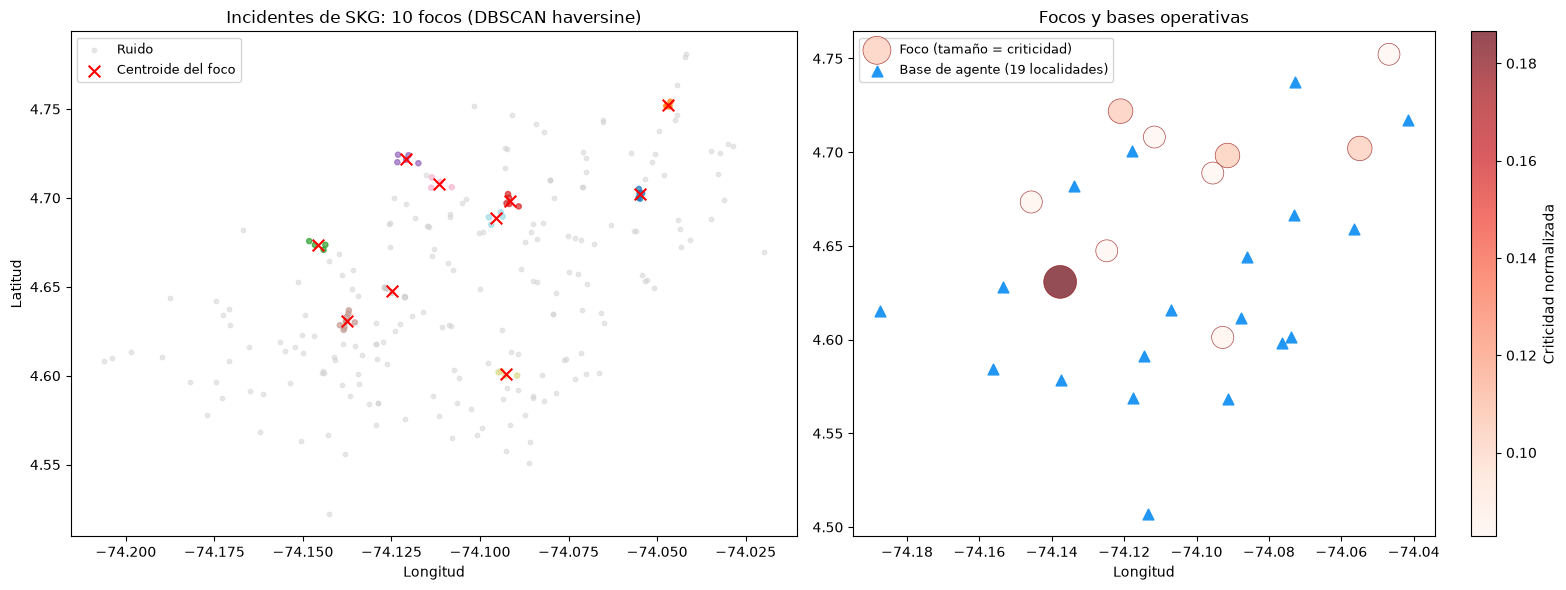

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ruido = incidents_df["cluster"] == -1
ax = axes[0]
ax.scatter(incidents_df.loc[ruido, "longitude"], incidents_df.loc[ruido, "latitude"], c="lightgrey", s=10, alpha=0.5, label="Ruido")
ax.scatter(incidents_df.loc[~ruido, "longitude"], incidents_df.loc[~ruido, "latitude"], c=incidents_df.loc[~ruido, "cluster"], cmap="tab20", s=14, alpha=0.7)
ax.scatter(focos_df["lon_centroid"], focos_df["lat_centroid"], c="red", marker="x", s=70, label="Centroide del foco")
ax.set_title(f"Incidentes de SKG: {len(focos_df)} focos (DBSCAN haversine)")
ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud"); ax.legend(fontsize=9)
ax = axes[1]
sc = ax.scatter(focos_df["lon_centroid"], focos_df["lat_centroid"], s=focos_df["criticidad"] * 3000, c=focos_df["criticidad"],
                cmap="Reds", alpha=0.7, edgecolors="darkred", linewidths=0.5, label="Foco (tamaño = criticidad)")
ax.scatter(agents_df["longitude"], agents_df["latitude"], marker="^", c="#2196F3", s=60, label=f"Base de agente ({N_AGENTS} localidades)", zorder=5)
plt.colorbar(sc, ax=ax, label="Criticidad normalizada")
ax.set_title("Focos y bases operativas"); ax.set_xlabel("Longitud"); ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(OUT_FIGURES / "02_optimizacion_focos_agentes.png", dpi=150, bbox_inches="tight")
plt.show()

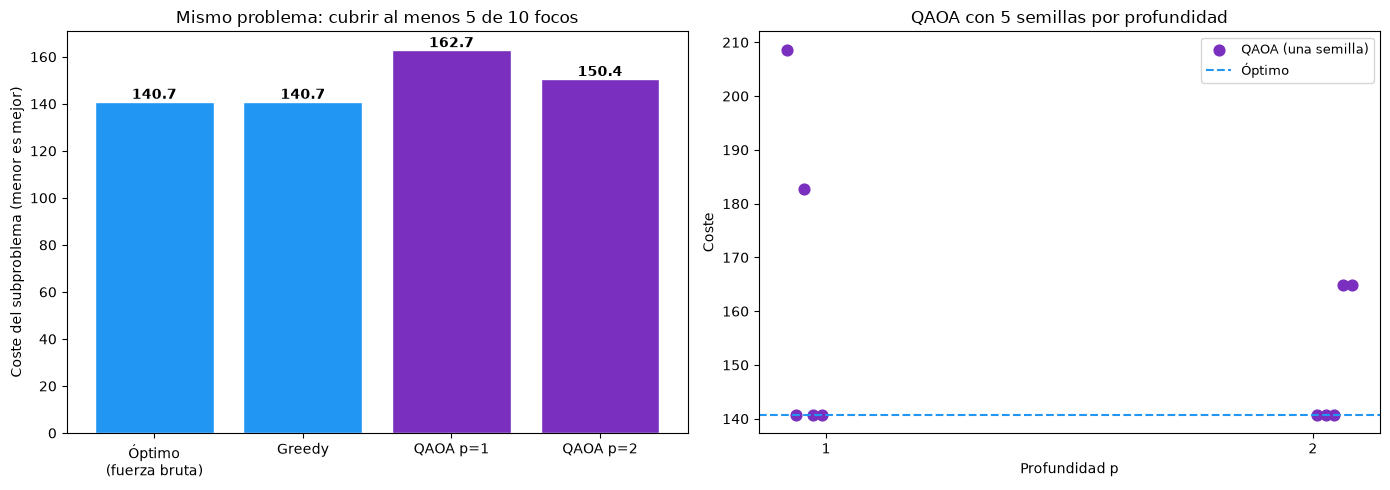

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
etiquetas = ["Óptimo\n(fuerza bruta)", "Greedy"] + [f"QAOA p={p}" for p in resumen_qaoa["p"]]
costes = [coste_opt, coste_greedy] + list(resumen_qaoa["coste_medio"])
colores = ["#2196F3", "#2196F3"] + ["#7B2FBE"] * len(resumen_qaoa)
barras = axes[0].bar(etiquetas, costes, color=colores, edgecolor="white")
for b, v in zip(barras, costes):
    axes[0].text(b.get_x() + b.get_width() / 2, v, f"{v:.1f}", ha="center", va="bottom", fontsize=10, fontweight="bold")
axes[0].set_ylabel("Coste del subproblema (menor es mejor)")
axes[0].set_title(f"Mismo problema: cubrir al menos {k} de {N_SUBPROBLEMA} focos")
axes[1].scatter(qaoa_df["p"] + np.linspace(-0.08, 0.08, len(qaoa_df)), qaoa_df["coste"], c="#7B2FBE", s=60, label="QAOA (una semilla)")
axes[1].axhline(coste_opt, color="#2196F3", linestyle="--", label="Óptimo")
axes[1].set_xticks([1, 2]); axes[1].set_xlabel("Profundidad p"); axes[1].set_ylabel("Coste")
axes[1].set_title(f"QAOA con {len(SEMILLAS_QAOA)} semillas por profundidad"); axes[1].legend(fontsize=9)
plt.tight_layout()
plt.savefig(OUT_FIGURES / "02_optimizacion_ventaja_cuantica.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Lectura

- En el **problema completo** solo se ejecuta el solver exacto clásico: QAOA necesitaría una variable binaria por pareja foco-agente y no cabe en el simulador.
- En el **subproblema** (10 focos, un agente), el óptimo y Greedy coinciden porque el objetivo es separable; la pregunta relevante es si QAOA, con el mismo presupuesto de 100 evaluaciones de COBYLA, encuentra una solución **factible y óptima**. Las cifras de la sección 7 responden con los resultados de cinco semillas por profundidad.
- Este cuaderno no mide ventaja cuántica de tiempo ni de calidad: el simulador de vector de estados es exponencial y el subproblema es trivial para métodos clásicos. La evaluación con protocolo completo de la asignación está en `qml_v2.optimization` (Caso de uso 3 de la memoria).